#### Apply gates in different orders

In [1]:
%pip install qiskit qiskit_aer pylatexenc
%pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 28.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 67.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 74.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [qiskit_aer]


In [2]:
# import necessary libraries
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

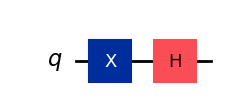

In [3]:
# Experiment A — Apply X followed by H

qc1 = QuantumCircuit(1)

qc1.x(0)
qc1.h(0)

qc1.draw("mpl")

In [4]:
state1 = Statevector.from_instruction(qc1)

print(state1)
print(state1.probabilities_dict())

Statevector([ 0.70710678+0.j, -0.70710678+0.j],
            dims=(2,))
{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


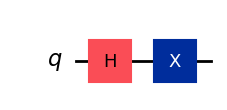

In [5]:
# Experiment B — Apply H followed by X

qc2 = QuantumCircuit(1)

qc2.h(0)
qc2.x(0)

qc2.draw("mpl")

In [6]:
state2 = Statevector.from_instruction(qc2)

print(state2)
print(state2.probabilities_dict())

Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))
{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


In [7]:
# Verify circuit equivalence: Check whether the original and optimized circuits produce equivalent quantum states.

print(state1.equiv(state2))  # Output: True if equivalent, False otherwise

False


#### Experiment with gate composition

In [8]:
# import necessary libraries
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

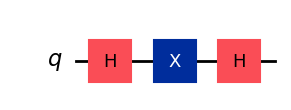

In [9]:
qc1 = QuantumCircuit(1)

qc1.h(0)
qc1.x(0)
qc1.h(0)

qc1.draw("mpl")

In [10]:
state1 = Statevector.from_instruction(qc1)

print(state1)
print(state1.probabilities_dict())

Statevector([1.+0.j, 0.+0.j],
            dims=(2,))
{np.str_('0'): np.float64(0.9999999999999996)}


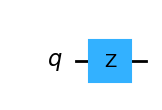

In [11]:
qc2 = QuantumCircuit(1)

qc2.z(0)

qc2.draw("mpl")

In [12]:
state2 = Statevector.from_instruction(qc2)

print(state2)
print(state2.probabilities_dict())

Statevector([1.+0.j, 0.+0.j],
            dims=(2,))
{np.str_('0'): np.float64(1.0)}


In [13]:
# Verify circuit equivalence: Check whether the original and optimized circuits produce equivalent quantum states.

print(state1.equiv(state2))  # Output: True if equivalent, False otherwise

True


#### Understand circuit depth

In [14]:
# import necessary libraries
from qiskit import QuantumCircuit
from qiskit.circuit.library import YGate

Gate count: 12
Circuit depth: 7


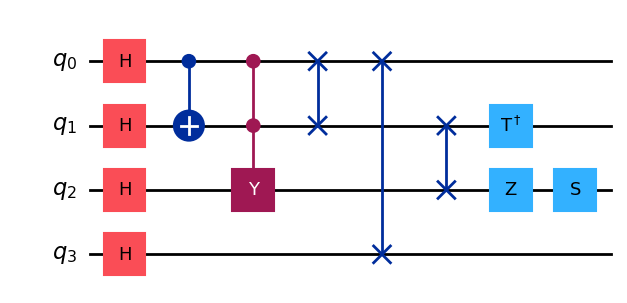

In [15]:
qc_a = QuantumCircuit(4)

# Single-qubit gates
qc_a.h(0)
qc_a.h(1)
qc_a.h(2)
qc_a.h(3)

# Controlled operations
qc_a.cx(0, 1)

ccy_gate = YGate().control(2)
qc_a.append(ccy_gate, [0, 1, 2])

# SWAP operations
qc_a.swap(0, 1)
qc_a.swap(0, 3)
# qc_a.z(2)       # Comment/Uncomment this line to see the effect of the Z gate on the circuit depth and gate count
qc_a.swap(1, 2)

# Single-qubit gates
qc_a.z(2)     # Comment/Uncomment this line to see the effect of the Z gate on the circuit depth and gate count
qc_a.tdg(1)
qc_a.s(2)

print("Gate count:", qc_a.size())
print("Circuit depth:", qc_a.depth())

qc_a.draw("mpl")

#### Explore gate decomposition

In [16]:
# import necessary libraries
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

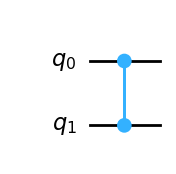

In [17]:
# A controlled-Z gate can be decomposed using Hadamard and CNOT gates.

qc1 = QuantumCircuit(2)

qc1.cz(0, 1)
qc1.draw("mpl")

In [18]:
state1 = Statevector.from_instruction(qc1)

print(state1)
print(state1.probabilities_dict())

Statevector([1.+0.j, 0.+0.j, 0.+0.j, 0.+0.j],
            dims=(2, 2))
{np.str_('00'): np.float64(1.0)}


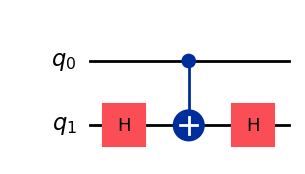

In [19]:
qc2 = QuantumCircuit(2)

qc2.h(1)
qc2.cx(0, 1)
qc2.h(1)

qc2.draw("mpl")

In [20]:
state2 = Statevector.from_instruction(qc2)

print(state2)
print(state2.probabilities_dict())

Statevector([ 1.00000000e+00+0.j,  0.00000000e+00+0.j, -2.23711432e-17+0.j,
              0.00000000e+00+0.j],
            dims=(2, 2))
{np.str_('00'): np.float64(0.9999999999999996), np.str_('10'): np.float64(5.004680467665246e-34)}


In [21]:
# Verify circuit equivalence: Check whether the original and optimized circuits produce equivalent quantum states.

print(state1.equiv(state2))  # Output: True if equivalent, False otherwise

True


#### Decompose a quantum circuit

Circuit decomposition is the process of breaking down a complex quantum gate or circuit into a sequence of simpler quantum gates while preserving the same quantum operation.

In [22]:
# import necessary libraries
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

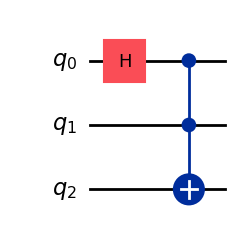

In [23]:
qc = QuantumCircuit(3)

qc.h(0)
qc.ccx(0, 1, 2)

qc.draw("mpl")

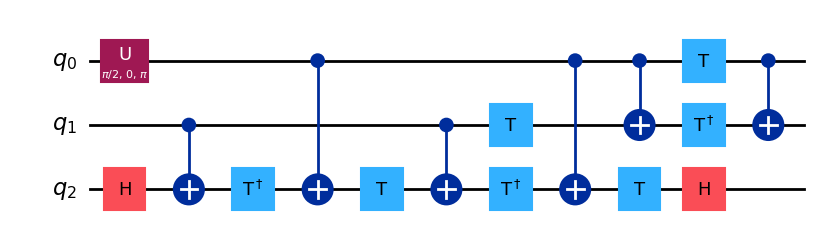

In [24]:
# Decompose the circuit:

qc_decomposed = qc.decompose()
qc_decomposed.draw("mpl")

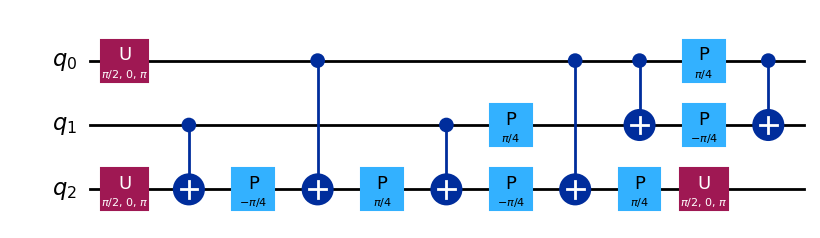

In [25]:
# Repeat the decomposition:

qc_decomposed_2 = qc.decompose(reps=2)
qc_decomposed_2.draw("mpl")

In [26]:
print("Original circuit", "Gate count:", qc.size(), "Depth:", qc.depth())
print("Decomposed circuit", "Gate count:", qc_decomposed_2.size(), "Depth:", qc_decomposed_2.depth())

Original circuit Gate count: 2 Depth: 2
Decomposed circuit Gate count: 16 Depth: 11


In [27]:
original_state = Statevector.from_instruction(qc)
decomposed_state = Statevector.from_instruction(qc_decomposed_2)

print("Original state:", original_state)
print("Decomposed state:", decomposed_state)
print("Equivalent:", original_state.equiv(decomposed_state))

Original state: Statevector([0.70710678+0.j, 0.70710678+0.j, 0.        +0.j,
             0.        +0.j, 0.        +0.j, 0.        +0.j,
             0.        +0.j, 0.        +0.j],
            dims=(2, 2, 2))
Decomposed state: Statevector([7.07106781e-01-4.32978028e-17j,
             7.07106781e-01-4.32978028e-17j,
             0.00000000e+00+0.00000000e+00j,
             0.00000000e+00+0.00000000e+00j,
             0.00000000e+00+4.32978028e-17j,
             2.29934717e-17+4.32978028e-17j,
             0.00000000e+00+0.00000000e+00j,
             0.00000000e+00+0.00000000e+00j],
            dims=(2, 2, 2))
Equivalent: True


#### Explore circuit optimization - Trnspilation

Create a circuit with redundant gate operations.

In [28]:
# import necessary libraries
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

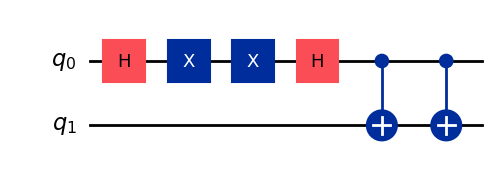

In [29]:
qc = QuantumCircuit(2)

qc.h(0)
qc.x(0)
qc.x(0)
qc.h(0)

qc.cx(0, 1)
qc.cx(0, 1)

# qc.x(1)

qc.draw("mpl")

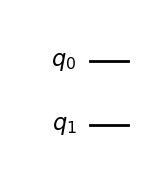

In [30]:
from qiskit import transpile

optimized_qc = transpile(
    qc,
    basis_gates=['u', 'cx'],
    optimization_level=3
)

optimized_qc.draw("mpl")

In [31]:
print("Original gate count:", qc.size())
print("Optimized gate count:", optimized_qc.size())

print("Original depth:", qc.depth())
print("Optimized depth:", optimized_qc.depth())

Original gate count: 6
Optimized gate count: 0
Original depth: 6
Optimized depth: 0


In [32]:
# Verify circuit equivalence: Check whether the original and optimized circuits produce equivalent quantum states.

original_state = Statevector.from_instruction(qc)
optimized_state = Statevector.from_instruction(optimized_qc)

print(original_state.equiv(optimized_state))

True


#### Let's see them all together

Composition, Decomposition, Optimization, Transpilation

In [33]:
# import necessary libraries
from qiskit import QuantumCircuit, transpile

Original     | Gates:   6 | Depth:   6
Composed     | Gates:   7 | Depth:   7
Decomposed   | Gates:  20 | Depth:  15
Optimized    | Gates:  15 | Depth:  11
Transpiled   | Gates:  20 | Depth:  15

Original Circuit:


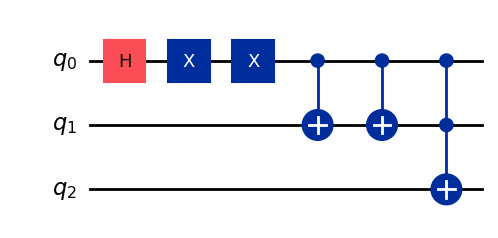


Composed Circuit:


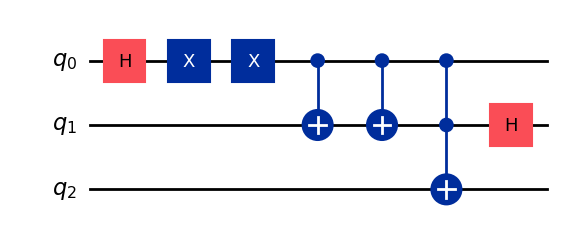


Decomposed Circuit:


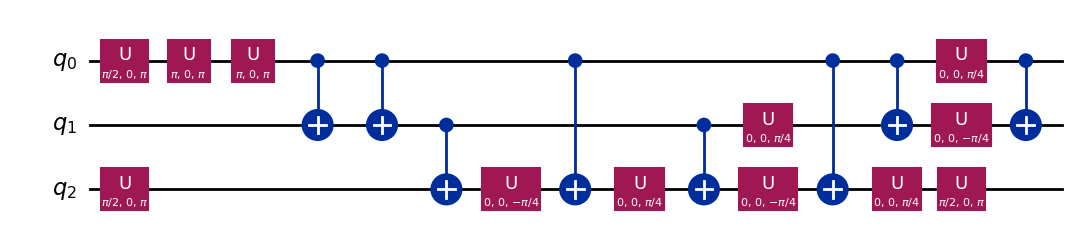


Optimized Circuit:


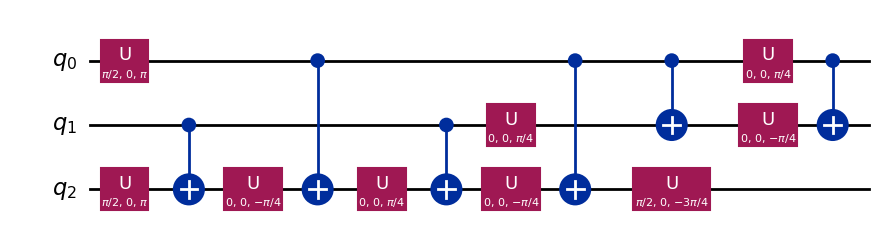


Transpiled Circuit:


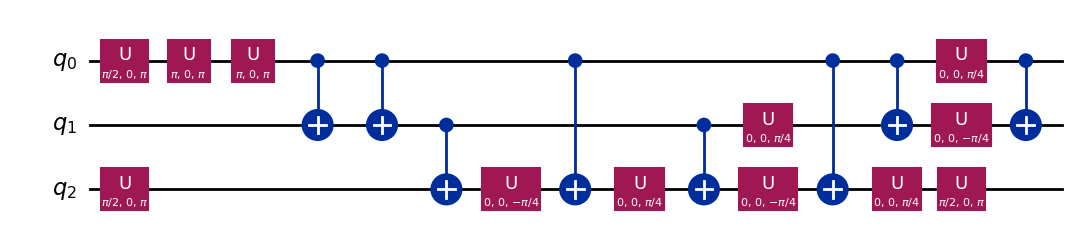

In [34]:
# Original circuit
qc = QuantumCircuit(3)

qc.h(0)
qc.x(0)
qc.x(0)
qc.cx(0, 1)
qc.cx(0, 1)
qc.ccx(0, 1, 2)

# 1. Composition
qc_extra = QuantumCircuit(3)
qc_extra.h(1)

composed = qc.compose(qc_extra)

# 2. Decomposition
decomposed = qc.decompose(reps=3)

# 3. Optimization
optimized = transpile(
    qc,
    basis_gates=['u', 'cx'],
    optimization_level=3
)

# 4. Transpilation
transpiled = transpile(
    qc,
    basis_gates=['u', 'cx'],
    optimization_level=0
)

# Compare
circuits = {
    "Original": qc,
    "Composed": composed,
    "Decomposed": decomposed,
    "Optimized": optimized,
    "Transpiled": transpiled
}

for name, circuit in circuits.items():
    print(
        f"{name:12} | "
        f"Gates: {circuit.size():3} | "
        f"Depth: {circuit.depth():3}"
    )

for name, circuit in circuits.items():
    print(f"\n{name} Circuit:")
    display(circuit.draw(output='mpl'))